In [14]:
%pip install numpy matplotlib imageio scikit-image>=0.25 scikit-learn ipywidgets ipykernel

In [15]:
import skimage
import numpy as np
import glob

from matplotlib import pyplot as plt
from imageio.v3 import imread
from skimage.feature import SIFT

from tqdm import tqdm
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import NearestNeighbors

In [16]:
# Magic
QUERY_K = 5

In [17]:
# STEP 1 =======================================================================

# Load all images in the Children Books Director
paths = sorted(glob.glob('Childrens-Books/*.jpg'))
train_images = []
for p in tqdm(paths, desc='processing images'):
    train_images.append(skimage.color.rgb2gray(imread(p)))

processing images: 100%|██████████| 984/984 [00:03<00:00, 261.81it/s]


In [18]:
# STEP 2 =======================================================================
SIFT_MODEL = SIFT()

def get_key_and_desc(img, sift=SIFT_MODEL):
  sift.detect_and_extract(img)
  keypoints = sift.keypoints
  descriptors = sift.descriptors

  return keypoints, descriptors

  # Get all descriptors for all images
descriptors = []
for t_img in tqdm(train_images, desc='detecting keypoints'):
    descriptors.append(get_key_and_desc(t_img)[1])
all_descriptors = np.concatenate(descriptors)

detecting keypoints: 100%|██████████| 984/984 [05:31<00:00,  2.96it/s]


In [19]:
# STEP 3 ===================================================================

# Cluster all descriptors into 1000 clusters
print('clustering descriptors with kmeans...')
kmeans = KMeans(n_clusters=1000, random_state=0, n_init="auto").fit(all_descriptors)
print('finished Clustering descriptors with kmeans!')

clustering descriptors with kmeans...
finished Clustering descriptors with kmeans!


In [20]:
# STEP 4 ===================================================================

# Use the KMeans clustering to convert each list of SIFT descriptors into a
# list of cluster labels (using .predict()).
cluster_labels = []
for desc in tqdm(descriptors, desc='converting to cluster labels'):
    cluster_labels.append(kmeans.predict(desc))

converting to cluster labels: 100%|██████████| 984/984 [00:05<00:00, 183.20it/s]


In [21]:
# STEP 5 ===================================================================

# Convert each list of cluster labels into a string (using str()). Now each
# image has been converted into a "text document"
txt_documents = []
for label in tqdm(cluster_labels, desc='converting labels to strings'):
    txt_documents.append(str(label))

converting labels to strings: 100%|██████████| 984/984 [00:01<00:00, 717.02it/s]


In [22]:
# STEP 6 ===================================================================

# Use sklearn.feature_extraction.text.TfidfVectorizer to convert each
# "document" to a tf-idf weighted histogram

print('converting documents to histograms...')
vectorizer = TfidfVectorizer()
train_hists = vectorizer.fit_transform(txt_documents)
print('finished converting documents to histograms!')

converting documents to histograms...
finished converting documents to histograms!


In [23]:
# STEP 7 =======================================================================

# Build a k nearest neighbors model on the histograms

print('fitting nearest neighbors model...')
knn_model = NearestNeighbors(metric='cosine')
knn_model.fit(train_hists)
print('finished fitting nearest neighbors model!')

fitting nearest neighbors model...
finished fitting nearest neighbors model!


In [24]:
# STEP 8 =======================================================================

# Load all query images
query_paths = sorted(glob.glob('queries/*.jpg'))
query_images = []
for q_p in tqdm(query_paths, desc='processing images'):
    query_images.append(skimage.color.rgb2gray(imread(q_p)))

query_descriptors = []
for q_img in tqdm(query_images, desc='detecting keypoints'):
    query_descriptors.append(get_key_and_desc(q_img)[1])

query_cluster_labels = []
for query_desc in tqdm(query_descriptors, desc='converting to cluster labels'):
    query_cluster_labels.append(kmeans.predict(query_desc))

query_documents = []
for label in tqdm(query_cluster_labels, desc='converting labels to strings'):
    query_documents.append(str(label))

print('converting documents to histograms...')
query_hists = vectorizer.transform(query_documents)
print('finished converting documents to histograms!')

converting labels to strings: 100%|██████████| 6/6 [00:00<00:00, 725.16it/s]

converting documents to histograms...
finished converting documents to histograms!


In [25]:
# STEP 9 =======================================================================

# use the knn model to predict the top QUERY_K closest documents
distances, indices = knn_model.kneighbors(query_hists, n_neighbors=QUERY_K)

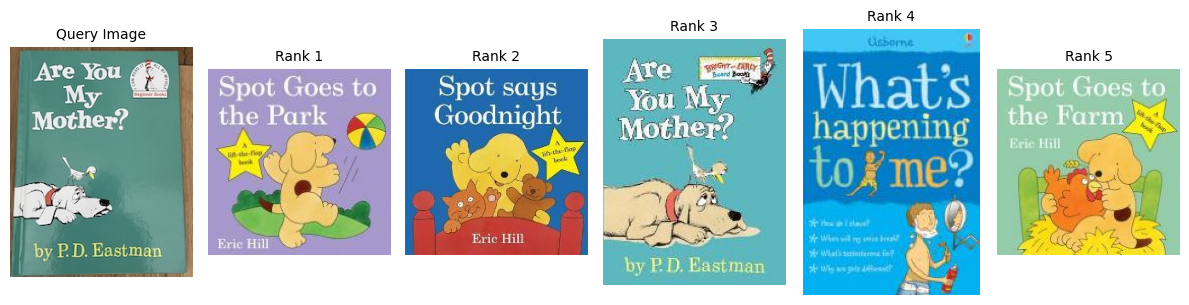

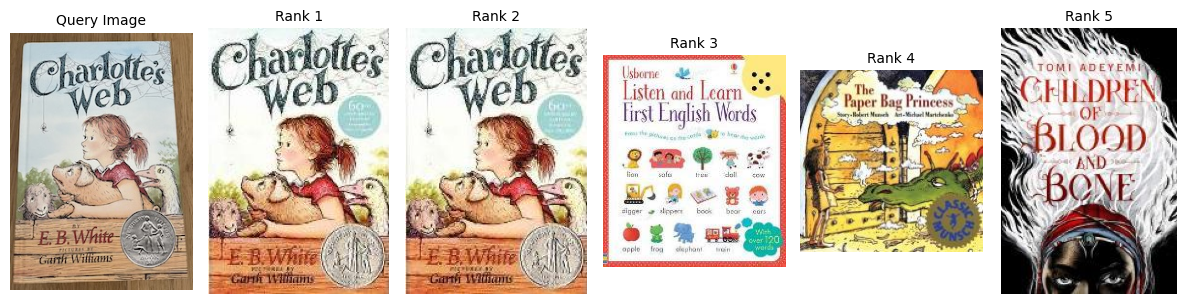

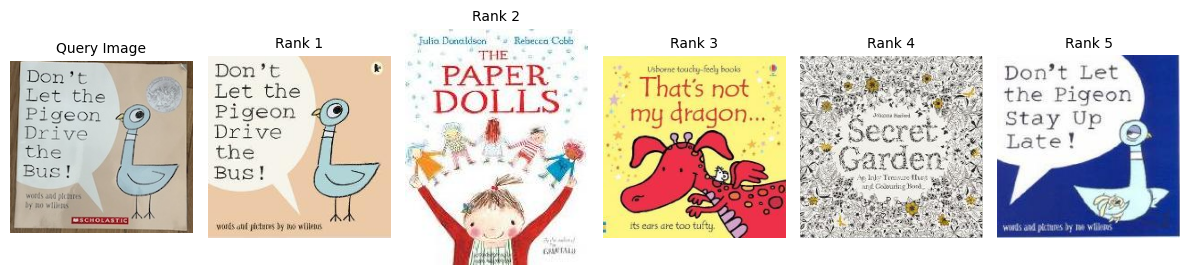

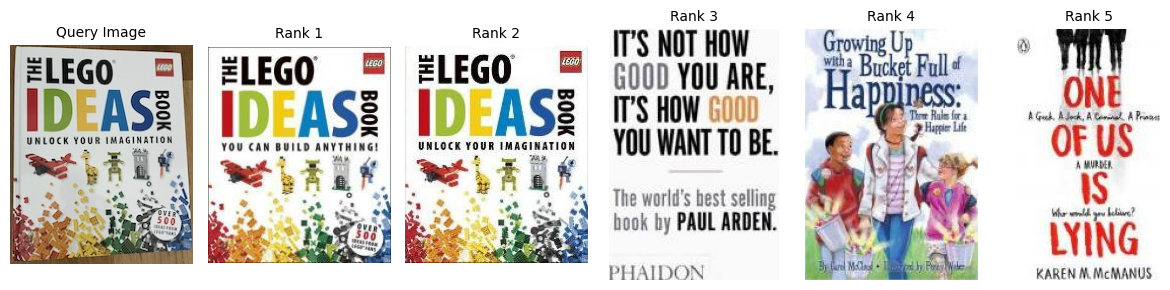

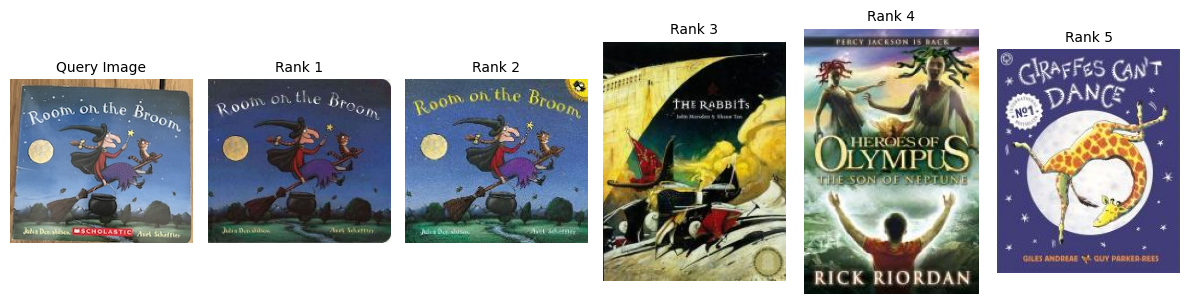

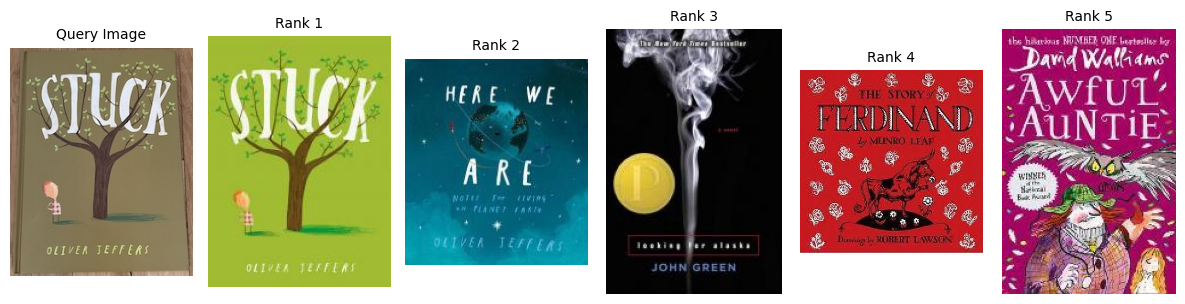

In [26]:
# STEP 10 ======================================================================

# Plot each query image next to its nearest neighbors
for i, q_path in enumerate(query_paths):
    # Create a row of subplots: 1 for the query + QUERY_K for neighbors
    fig, axes = plt.subplots(1, QUERY_K + 1, figsize=(2 * (QUERY_K + 1), 3))

    # Plot the query image
    axes[0].imshow(plt.imread(q_path))
    axes[0].set_title("Query Image", fontsize=10)
    axes[0].axis('off')

    # Plot each nearest neighbor
    for j, neighbor_idx in enumerate(indices[i]):
        neighbor_path = paths[neighbor_idx]
        axes[j + 1].imshow(plt.imread(neighbor_path))
        axes[j + 1].set_title(f"Rank {j+1}", fontsize=10)
        axes[j + 1].axis('off')

    plt.tight_layout()
    plt.show()